# 22 — Storage units and flow divider nodes

Storage units represent water held in a pond, tank or other volume. Their surface
area varies with depth. Flow dividers send part of their inflow into a selected
outgoing link. This notebook builds, edits, validates, saves, exports and simulates
both types using SWMMX 0.0.43 or later.

Use **Run All** from the repository root or `examples/`. The simulation uses the
bundled EPA engine. NumPy, pandas, matplotlib and networkx are required; Excel
needs openpyxl and the GIS cell needs geopandas, shapely, pyproj and a GIS I/O
backend (pyogrio or Fiona). Files go into `examples/output/22_storage_dividers/`.

EPA references: [SWMM 5.2 manual](https://nepis.epa.gov/Exe/ZyPURL.cgi?Dockey=P10145M6.TXT)
and [the node input parser](https://github.com/USEPA/Stormwater-Management-Model/blob/develop/src/solver/node.c).
Dividers operate under Steady or Kinematic Wave routing; Dynamic Wave treats them
as junctions. We explicitly select Kinematic Wave for the flow comparisons.

In [1]:
from pathlib import Path
import sys
import importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if ROOT.name == 'examples':
    ROOT = ROOT.parent
if (ROOT / 'src' / 'swmmx').exists():
    sys.path.insert(0, str(ROOT / 'src'))
from swmmx import swmm, InvalidParameterError, InvalidReferenceError, DependencyError, NotImplementedYetError

OUT = ROOT / 'examples' / 'output' / '22_storage_dividers'
OUT.mkdir(parents=True, exist_ok=True)

## Minimal construction and the two-phase divider connection

`area=100` describes a constant area of 100 m² in an SI model. It aliases
`area_constant`. The full FUNCTIONAL formula is
`area_coefficient * depth ** area_exponent + area_constant`.
TABULAR storage instead requires an existing STORAGE curve; mixing tabular and
functional inputs raises an error. Inapplicable getters return `None`.

A newly created divider can temporarily use `diverted_link='*'`. Add its links,
then set the diverted link. A named link must exist and leave the divider.
`validate()` reports an unassigned diverted link as an error until it is set.

In [2]:
minimal = swmm(new='SI', flow_unit='CMS')
minimal.add.node.storage_unit('Tank', x=0, y=0, invert_elevation=2,
                              max_depth=3, area=100, tag='Detention')
minimal.add.node.divider('Split', x=100, y=0, invert_elevation=1,
                         max_depth=3, type='CUTOFF', cutoff_flow=0.05)
minimal.add.node.outfall('River', x=200, y=50, invert_elevation=0)
minimal.add.node.outfall('BypassOut', x=200, y=-50, invert_elevation=0)
minimal.add.link.conduit('Feed', from_node='Tank', to_node='Split', length=100)
minimal.add.link.conduit('Normal', from_node='Split', to_node='River', length=100)
minimal.add.link.conduit('Bypass', from_node='Split', to_node='BypassOut', length=100)
minimal.set.flow_divider.diverted_link('Bypass', ids='Split')
assert minimal.validate().ok
print('STORAGE:', minimal.section('STORAGE'))
print('DIVIDERS:', minimal.section('DIVIDERS'))
print('Coordinates:', minimal.get.node.coordinate(ids='Tank'))

STORAGE: [['Tank', '2.0', '3.0', '0.0', 'FUNCTIONAL', '0.0', '0.0', '100.0', '0.0', '0.0', '0.0', '0.0', '0.0']]
DIVIDERS: [['Split', '1.0', 'Bypass', 'CUTOFF', '0.05', '3.0', '0.0', '0.0', '0.0']]
Coordinates: (0.0, 0.0)


## A two-compartment detention system

The upstream pond starts with stored water and drains through a second pond to
a divider. We compare all four divider rules with identical pipes and initial
conditions. This is a drawdown example, not a calibrated design model.

The first pond uses a functional area relation and the second a surveyed table.
`seepage_loss=(Psi, Ksat, IMD)` supplies suction head, saturated hydraulic
conductivity and initial moisture deficit. A scalar `seepage_loss` is a Ksat
shorthand. Its getter returns Ksat; the three named getters preserve all inputs.
Suction head and Ksat use SWMM's infiltration units (mm and mm/hour for SI).
Evaporation factor is between zero and one. Surcharge depth is also supported.

| Divider | Required parameters |
|---|---|
| OVERFLOW | No additional relation parameters |
| CUTOFF | cutoff_flow |
| TABULAR | diversion_curve referring to a DIVERSION curve |
| WEIR | cutoff_flow (minimum flow), weir_height, weir_coefficient |

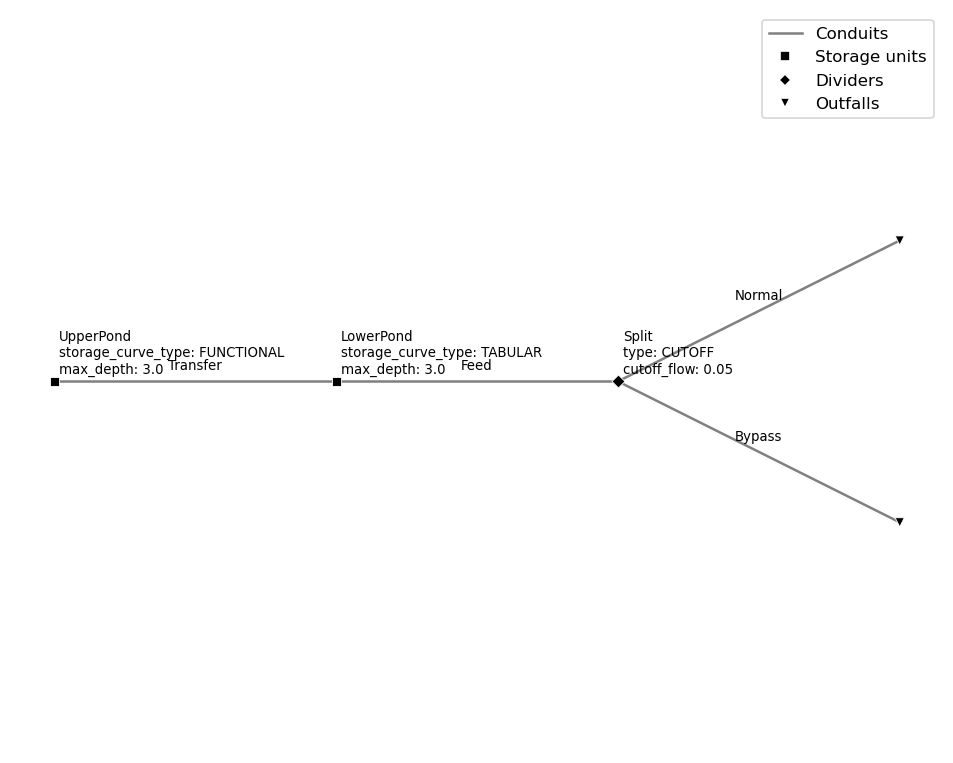

In [3]:
def detention_system(kind):
    m = swmm(new='SI', flow_unit='CMS')
    m.options['FLOW_ROUTING'] = 'KINWAVE'
    m.options['END_DATE'] = m.options['START_DATE']
    m.options['END_TIME'] = '03:00:00'
    m.options['REPORT_STEP'] = '00:01:00'
    m.add.curve.storage('SurveyedArea', [(0, 150), (1, 220), (2, 350), (3, 500)])
    m.add.curve.diversion('DiversionTable', [(0, 0), (0.05, 0), (0.2, 0.08), (1, 0.5)])
    m.add.node.storage_unit('UpperPond', x=0, y=0, invert_elevation=6,
        max_depth=3, initial_depth=1.5, storage_curve_type='FUNCTIONAL',
        area_coefficient=40, area_exponent=1, area_constant=300,
        surcharge_depth=0.2, evaporation_factor=0.7,
        seepage_loss=(75, 1.5, 0.25), tag='Upper detention')
    m.add.node.storage_unit('LowerPond', x=120, y=0, invert_elevation=4,
        max_depth=3, initial_depth=0.2, storage_curve_type='TABULAR',
        storage_curve='SurveyedArea', tag='Surveyed basin')
    parameters = {
        'CUTOFF': dict(cutoff_flow=0.05),
        'OVERFLOW': {},
        'TABULAR': dict(diversion_curve='DiversionTable'),
        'WEIR': dict(cutoff_flow=0.02, weir_height=0.5, weir_coefficient=1.8),
    }[kind]
    m.add.node.divider('Split', x=240, y=0, invert_elevation=2,
        max_depth=3, type=kind, tag='Outlet splitter', **parameters)
    m.add.node.outfall('River', x=360, y=60, invert_elevation=0)
    m.add.node.outfall('BypassOut', x=360, y=-60, invert_elevation=0)
    for name, first, last, diameter in [
        ('Transfer', 'UpperPond', 'LowerPond', 0.4),
        ('Feed', 'LowerPond', 'Split', 0.5),
        ('Normal', 'Split', 'River', 0.3),
        ('Bypass', 'Split', 'BypassOut', 0.5),
    ]:
        m.add.link.conduit(name, from_node=first, to_node=last,
                           length=120, diameter=diameter, roughness=0.013)
    m.set.flow_divider.diverted_link('Bypass', ids='Split')
    assert m.validate().ok
    return m

models = {kind: detention_system(kind) for kind in ['CUTOFF', 'TABULAR', 'WEIR', 'OVERFLOW']}
m = models['CUTOFF']
m.plot_layout(annotation={
    'storage_units': {'fields': ['id', 'storage_curve_type', 'max_depth']},
    'dividers': {'fields': ['id', 'type', 'cutoff_flow']},
    'conduits': {'fields': ['id']},
})
plt.show()

## Validation and conservative removal

Invalid edits are checked before rows are written. Referenced curves cannot be
removed. Node removal blocks dependencies; `force=True` can remove connected
conduits only when they have no remaining divider/control references. Subcatchment
outlets, other link types and complex attached records need explicit handling.
Relation-type changes accept a mapping or a complete import update so required
fields arrive together; a scalar type setter rejects a change that would discard parameters.

In [4]:
for description, action, error in [
    ('Missing curve', lambda: m.set.storage_unit.storage_curve('Missing', ids='LowerPond'), InvalidReferenceError),
    ('Negative depth', lambda: m.set.storage_unit.max_depth(-1, ids='UpperPond'), InvalidParameterError),
    ('Referenced node', lambda: m.remove.node.storage_unit('UpperPond'), DependencyError),
    ('Referenced link', lambda: m.remove.link.conduit('Bypass', force=True), NotImplementedYetError),
]:
    try:
        action()
    except error as exc:
        print(f'{description}: {exc}')
    else:
        raise AssertionError('Expected a validation error')

removal_demo = m.clone()
print(removal_demo.remove.node.storage_unit('UpperPond', force=True))
removal_demo.add.node.divider('Unused', x=0, y=100)
print(removal_demo.remove.node.divider('Unused'))
assert m.get.storage_unit.count() == 2

changed_relation = m.clone()
changed_relation.set.flow_divider.type(
    {'type': 'WEIR', 'cutoff_flow': 0.02, 'weir_height': 0.5, 'weir_coefficient': 1.8},
    ids='Split')
assert changed_relation.get.flow_divider.type(ids='Split') == 'WEIR'

Missing curve: Curve 'Missing' must reference an existing STORAGE curve.
Negative depth: max_depth must be finite and non-negative.
Referenced node: Cannot remove storage_unit 'UpperPond' because it is referenced by conduit 'Transfer'. Use force=True only if you want to remove dependent objects or references.
Referenced link: Conduit removal would break divider/control references; automatic rewriting is not implemented yet.
{'removed': ['UpperPond'], 'warnings': [], 'dependencies_removed': ['conduit:Transfer']}
{'removed': ['Unused'], 'warnings': [], 'dependencies_removed': []}


## Save/reopen and CSV, Excel and GIS interchange

CSV and GIS use `node.storage_unit` and `node.flow_divider`. Exports include x/y,
tags and named hydraulic fields. Import updates below use a clone with existing
links and curves. For a new network import curves, create nodes with `*` divider
links, import links, and finally update the dividers with their diverted links.

In [5]:
saved = m.save(OUT / 'detention.inp')
reopened = swmm(saved)
assert reopened.section('STORAGE') == m.section('STORAGE')
assert reopened.section('DIVIDERS') == m.section('DIVIDERS')
assert reopened.get.storage_unit.tag(ids='UpperPond') == 'Upper detention'
csv_files = m.export.csv(path=OUT / 'csv', elements=['storage_units', 'dividers'],
                         include_results=False, overwrite=True)
roundtrip = m.clone()
assert roundtrip.import_csv.node.storage_unit(csv_files['storage_units'], mode='update').ok
assert roundtrip.import_csv.node.flow_divider(csv_files['dividers'], mode='update').ok
assert roundtrip.section('STORAGE') == m.section('STORAGE')
assert roundtrip.section('DIVIDERS') == m.section('DIVIDERS')
display(pd.read_csv(csv_files['storage_units']))

if importlib.util.find_spec('openpyxl'):
    workbook = m.export.excel(path=OUT, file_name='storage_dividers.xlsx',
        elements=['storage_units', 'dividers'], include_results=False, overwrite=True)
    display(pd.read_excel(workbook, sheet_name='dividers'))
else:
    print('Excel example skipped: install openpyxl to run it.')

,id,invert_elevation,max_depth,initial_depth,storage_curve_type,area_coefficient,area_exponent,area_constant,surcharge_depth,evaporation_factor,suction_head,hydraulic_conductivity,initial_moisture_deficit,area,seepage_loss,tag,storage_curve,coordinates,x,y
0,UpperPond,6.0,3.0,1.5,FUNCTIONAL,40.0,1.0,300.0,0.2,0.7,75.0,1.5,0.25,300.0,1.5,Upper detention,NaN,"[0.0,0.0]",0.0,0.0
1,LowerPond,4.0,3.0,0.2,TABULAR,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.00,NaN,0.0,Surveyed basin,SurveyedArea,"[120.0,0.0]",120.0,0.0


,id,invert_elevation,diverted_link,type,cutoff_flow,max_depth,initial_depth,surcharge_depth,ponded_area,tag,coordinates,x,y
0,Split,2,Bypass,CUTOFF,0.05,3,0,0,0,Outlet splitter,"[240.0,0.0]",240,0


In [6]:
if all(importlib.util.find_spec(name) for name in ['geopandas', 'shapely', 'pyproj']):
    # Coordinates here are schematic; the assigned CRS is for demonstrating I/O.
    m.export.gis(path=OUT, file_name='storage_dividers.gpkg', driver='GPKG',
        elements=['storage_units', 'dividers'], crs='EPSG:27700',
        include_results=False, overwrite=True)
    gpkg = OUT / 'storage_dividers.gpkg'
    assert roundtrip.import_gis.node.storage_unit(gpkg, layer='storage_units', mode='update').ok
    assert roundtrip.import_gis.node.flow_divider(gpkg, layer='dividers', mode='update').ok
    assert roundtrip.get.storage_unit.hydraulic_conductivity(ids='UpperPond') == 1.5
    assert roundtrip.get.flow_divider.diverted_link(ids='Split') == 'Bypass'
    print('GeoPackage round trip verified:', gpkg)
else:
    print('GIS example skipped: install geopandas shapely pyproj pyogrio to run it.')

GeoPackage round trip verified: C:\Users\Mohammadali\Documents\My_Codes\swmmx_dev\examples\output\22_storage_dividers\storage_dividers.gpkg


## Run and compare the divider rules

All four scenarios have the same initial stored volume. Compare pond drawdown and
bypass flow through native node/link outputs. Separate saved files keep each
scenario's output independent. Edits invalidate these outputs until the next run.

Editing the pond marks its simulation results stale: True


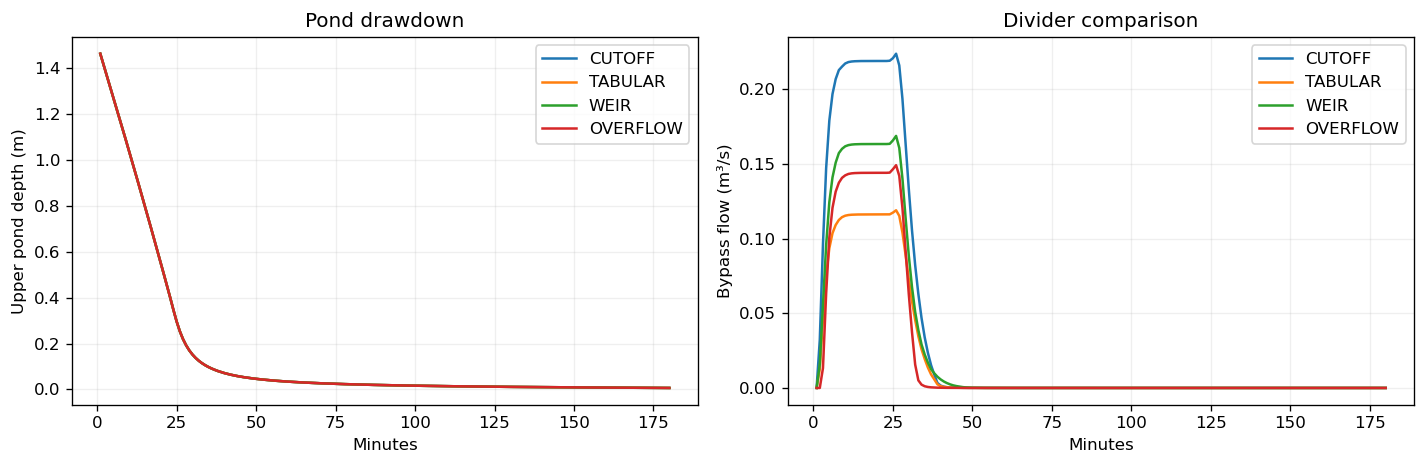

,divider,peak_bypass_m3_s,final_upper_depth_m,peak_split_inflow_m3_s
0,CUTOFF,0.223790,0.00673,0.27418
1,TABULAR,0.118967,0.00673,0.27418
2,WEIR,0.168762,0.00673,0.27418
3,OVERFLOW,0.149150,0.00673,0.27418


In [7]:
comparison = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for kind, scenario in models.items():
    scenario.save(OUT / f'detention_{kind.lower()}.inp')
    result = scenario.run()
    assert result.success, scenario.log()
    depth = scenario.get.storage_unit.depth(ids='UpperPond').ravel()
    bypass = scenario.get.conduit.flow(ids='Bypass').ravel()
    minutes = np.arange(1, len(depth) + 1)
    axes[0].plot(minutes, depth, label=kind)
    axes[1].plot(minutes, bypass, label=kind)
    comparison.append({'divider': kind, 'peak_bypass_m3_s': bypass.max(),
                       'final_upper_depth_m': depth[-1],
                       'peak_split_inflow_m3_s': scenario.get.flow_divider.total_inflow(ids='Split').max()})
axes[0].set(xlabel='Minutes', ylabel='Upper pond depth (m)', title='Pond drawdown')
axes[1].set(xlabel='Minutes', ylabel='Bypass flow (m³/s)', title='Divider comparison')
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUT / 'divider_comparison.png', dpi=150)
plt.show()
display(pd.DataFrame(comparison))

edited = models['OVERFLOW']
edited.set.storage_unit.area_constant(350, ids='UpperPond')
assert edited.modified and edited.results_stale and not edited.has_run
print('Editing the pond marks its simulation results stale:', edited.results_stale)
edited.set.storage_unit.area_constant(300, ids='UpperPond')  # Restore input; rerun is still required.

## Final object and setting summary

The table combines the two ponds, flow divider, two outfalls and four conduits.
The four scenarios differ only in their divider relation. All storage parameters,
including evaporation, surcharge and three seepage inputs, survive save/reopen
and the interchange examples above.

EPA 5.2 analytical storage shapes are also accepted: CYLINDRICAL, CONICAL,
PARABOLIC and PYRAMIDAL. In these modes `area_coefficient`, `area_exponent`,
`area_constant` carry EPA's three geometry tokens (length, width, slope/height),
not a power-law equation. See the manual before choosing an analytical shape.

In [8]:
summary_files = m.export.csv(path=OUT / 'summary', elements=['nodes', 'conduits'],
                             include_results=False, overwrite=True)
nodes = pd.read_csv(summary_files['nodes'])
links = pd.read_csv(summary_files['conduits'])
summary = pd.concat([
    nodes[['id', 'element_type', 'invert_elevation', 'max_depth', 'x', 'y']],
    links[['id', 'from_node', 'to_node', 'length']].assign(element_type='conduit'),
], ignore_index=True).fillna('')
display(summary)
display(pd.DataFrame([
    {'setting': 'Flow units', 'value': m.options['FLOW_UNITS']},
    {'setting': 'Routing', 'value': m.options['FLOW_ROUTING']},
    {'setting': 'Storage units per scenario', 'value': m.get.storage_unit.count()},
    {'setting': 'Dividers per scenario', 'value': m.get.flow_divider.count()},
    {'setting': 'Divider scenarios simulated', 'value': len(models)},
    {'setting': 'Output directory', 'value': str(OUT)},
]))

,id,element_type,invert_elevation,max_depth,x,y,from_node,to_node,length
0,River,outfall,0.0,,360.0,60.0,,,
1,BypassOut,outfall,0.0,,360.0,-60.0,,,
2,Split,divider,2.0,3.0,240.0,0.0,,,
3,UpperPond,storage_unit,6.0,3.0,0.0,0.0,,,
4,LowerPond,storage_unit,4.0,3.0,120.0,0.0,,,
5,Transfer,conduit,,,,,UpperPond,LowerPond,120.0
6,Feed,conduit,,,,,LowerPond,Split,120.0
7,Normal,conduit,,,,,Split,River,120.0
8,Bypass,conduit,,,,,Split,BypassOut,120.0


,setting,value
0,Flow units,CMS
1,Routing,KINWAVE
2,Storage units per scenario,2
3,Dividers per scenario,1
4,Divider scenarios simulated,4
5,Output directory,C:\Users\Mohammadali\Documents\My_Codes\swmmx_...
